# Mobile Network Traffic Forecasting — Milan (v1)

**Goal:** forecast tomorrow's **hourly internet traffic for every cell** of a mobile network, one day ahead.
Operators use forecasts like this for capacity planning, and for energy saving (putting lightly-loaded cells to sleep at night).

**Data:** Telecom Italia Big Data Challenge — Milan, 1 Nov 2013 → 1 Jan 2014. The city is split into a 100×100 grid of ~235 m squares; activity is recorded every 10 minutes per square (SMS, calls, internet). Values are anonymised and unitless.
*Source: Harvard Dataverse, doi:10.7910/DVN/EGZHFV — "from BigDataChallenge contest", ODbL licence.*

**Plan**
1. Download the 62 daily files and aggregate them to an hourly matrix (hours × squares).
2. Data-quality checks (missing 10-minute intervals).
3. Exploratory analysis: daily/weekly cycles, holidays, spatial patterns.
4. Baselines: yesterday, last week, 3-week weekly profile.
5. **One global LightGBM model** trained across 2,000 cells with lag features.
6. Evaluation on a held-out test period, plus a **Christmas stress test**.

**Time split (day-ahead forecasts, made at midnight for the next 24 hours)**

| Period | Dates | Used for |
|---|---|---|
| Warm-up | 1–7 Nov | lag features only |
| Train | 8–24 Nov | fitting |
| Validation | 25 Nov – 1 Dec | early stopping (a normal week) |
| Refit | 8 Nov – 8 Dec | final model, trained on train + validation + one more week |
| **Test** | **9–22 Dec** | final score (touched once) |
| Holiday stress test | 23 Dec – 1 Jan | how models behave on unusual days |

In [1]:
#0 — Settings

import os, glob, io, gzip, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SOURCE = "kaggle"                 # "kaggle" (recommended) | "dataverse" | "local" = files you put in DATA_DIR
KAGGLE_DATASET = "freckled/telecom"   # Kaggle mirror of the full Milan data (~5 GB)
DATAVERSE_TOKEN = ""              # only for SOURCE="dataverse": your Harvard Dataverse API token
DATA_DIR = "/content/milan_raw"   # raw daily files (deleted after processing to save disk)
OUT_DIR = "/content/milan_out"    # processed data, figures, results
DELETE_RAW_AFTER_PROCESSING = True
N_CELLS = 2000                    # cells used for modelling (random sample of active cells)
SEED = 42

DATAVERSE_DOI = "doi:10.7910/DVN/EGZHFV"
START = pd.Timestamp("2013-11-01")          # local time, Europe/Rome
N_DAYS, N_SQUARES = 62, 10_000
N_HOURS = N_DAYS * 24
T0_MS = 1383260400000                       # 2013-11-01 00:00 Europe/Rome, in ms since epoch (UTC)

# Holidays and holiday eves in Milan during the period
SPECIAL_DAYS = {
    "2013-11-01": "All Saints",
    "2013-12-07": "Sant'Ambrogio (Milan)",
    "2013-12-08": "Immaculate Conception",
    "2013-12-24": "Christmas Eve",
    "2013-12-25": "Christmas",
    "2013-12-26": "St Stephen",
    "2013-12-31": "New Year's Eve",
    "2014-01-01": "New Year",
}

FIG_DIR = os.path.join(OUT_DIR, "figures")
for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

dates = START + pd.to_timedelta(np.arange(N_DAYS), unit="D")
special = np.isin(dates, pd.to_datetime(list(SPECIAL_DAYS)))

def day_idx(s):
    return (pd.Timestamp(s) - START).days

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=120, bbox_inches="tight")

## 1. Load the raw data into an hourly matrix

Each raw daily file has one row per *(square, 10-minute interval, country code)*. We sum over country codes and over the six 10-minute intervals of each hour, which gives three matrices of shape **1,488 hours × 10,000 squares** (internet, calls, SMS). We also record which 10-minute intervals exist, to catch gaps.

The reader handles both the original tab-separated files (no header, timestamps in ms) and CSV versions with a header (e.g. from Kaggle).

**Data source options (cell 0, `SOURCE`)**
* `"kaggle"` (default): downloads the Kaggle mirror with `kagglehub` (preinstalled in Colab, no login needed for public datasets). About 5 GB.
* `"dataverse"`: the original Harvard Dataverse files. Harvard may block anonymous API requests from Colab (403 error); a free account + API token (`DATAVERSE_TOKEN`) usually solves it.
* `"local"`: put the daily files (or a zip of them) in `DATA_DIR` yourself.

In [2]:
#1 — Reader + accumulators

internet = np.zeros(N_HOURS * N_SQUARES)
calls = np.zeros(N_HOURS * N_SQUARES)
sms = np.zeros(N_HOURS * N_SQUARES)
present = np.zeros(N_HOURS * 6, dtype=bool)        # which 10-minute intervals were seen
processed_files = []

CANON = ["square", "time", "country", "sms_in", "sms_out", "call_in", "call_out", "internet"]

def _open_text(path):
    if path.endswith(".gz"):
        return gzip.open(path, "rt")
    if path.endswith(".zip"):
        zf = zipfile.ZipFile(path)
        return io.TextIOWrapper(zf.open(zf.namelist()[0]))
    return open(path, "rt")

def _norm(name):
    return "".join(ch for ch in name.lower() if ch.isalnum())

def _detect_format(path):
    with _open_text(path) as fh:
        line = fh.readline().rstrip("\n")
    sep = "\t" if "\t" in line else ","
    tokens = [t.strip().strip('"') for t in line.split(sep)]
    try:
        float(tokens[0]); has_header = False
    except ValueError:
        has_header = True
    positions = {c: i for i, c in enumerate(CANON)}          # default: original raw column order
    if has_header:
        names = [_norm(t) for t in tokens]
        lookup = {
            "square": [i for i, n in enumerate(names) if "cell" in n or "square" in n],
            "time": [i for i, n in enumerate(names) if "time" in n or "date" in n],
            "sms_in": [i for i, n in enumerate(names) if n == "smsin"],
            "sms_out": [i for i, n in enumerate(names) if n == "smsout"],
            "call_in": [i for i, n in enumerate(names) if n == "callin"],
            "call_out": [i for i, n in enumerate(names) if n == "callout"],
            "internet": [i for i, n in enumerate(names) if "internet" in n],
        }
        if all(len(v) == 1 for v in lookup.values()):
            positions = {k: v[0] for k, v in lookup.items()}
    return sep, has_header, positions

def process_file(path):
    sep, has_header, pos = _detect_format(path)
    use = ["square", "time", "sms_in", "sms_out", "call_in", "call_out", "internet"]
    reader = pd.read_csv(path, sep=sep, header=None, skiprows=1 if has_header else 0,
                         usecols=[pos[c] for c in use], chunksize=3_000_000, low_memory=False)
    for chunk in reader:
        chunk = chunk.rename(columns={pos[c]: c for c in use})
        t = chunk["time"]
        if pd.api.types.is_numeric_dtype(t):
            t = t.astype("float64")
            ms = np.where(t > 1e11, t, t * 1000)                                 # ms or s since epoch
            minutes = (ms - T0_MS) / 60_000
        else:
            ts = pd.to_datetime(t)
            if ts.dt.tz is not None:
                ts = ts.dt.tz_convert("Europe/Rome").dt.tz_localize(None)
            minutes = ((ts - START) / pd.Timedelta(minutes=1)).to_numpy()
        minutes = np.asarray(minutes, dtype="float64")
        sq = pd.to_numeric(chunk["square"], errors="coerce").to_numpy()
        hour = np.floor(minutes / 60)
        ok = (hour >= 0) & (hour < N_HOURS) & (sq >= 1) & (sq <= N_SQUARES)
        hour, sq, minutes = hour[ok].astype(np.int64), sq[ok].astype(np.int64), minutes[ok]
        idx = hour * N_SQUARES + (sq - 1)
        vals = chunk.loc[ok, ["sms_in", "sms_out", "call_in", "call_out", "internet"]].fillna(0).to_numpy("float64")
        internet[:] += np.bincount(idx, weights=vals[:, 4], minlength=N_HOURS * N_SQUARES)
        calls[:] += np.bincount(idx, weights=vals[:, 2] + vals[:, 3], minlength=N_HOURS * N_SQUARES)
        sms[:] += np.bincount(idx, weights=vals[:, 0] + vals[:, 1], minlength=N_HOURS * N_SQUARES)
        if np.all(np.mod(minutes, 60) == 0):        # file is already hourly
            for k in range(6):
                present[np.unique(hour) * 6 + k] = True
        else:
            present[np.unique(np.floor(minutes / 10).astype(np.int64))] = True
    processed_files.append(os.path.basename(path))

In [3]:
#2 — Get the files and process them one by one (download -> aggregate -> delete)
#    The full dataset is several GB; expect roughly 15–40 minutes depending on Colab's connection.

import requests

def find_daily_files(folder):
    files = sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True) if os.path.isfile(p))
    daily = [p for p in files if "sms-call-internet" in os.path.basename(p)]
    if not daily:                       # unexpected names: fall back to any data file, but show what we found
        daily = [p for p in files if p.endswith((".csv", ".txt", ".gz", ".zip")) and "province" not in p]
        print("No 'sms-call-internet' files found; using:", [os.path.basename(p) for p in daily][:10], "...")
    return daily

def process_folder(folder):
    daily = find_daily_files(folder)
    print(f"{len(daily)} daily files")
    for i, p in enumerate(daily, 1):
        t0 = time.time()
        process_file(p)
        print(f"[{i:2d}/{len(daily)}] {os.path.basename(p)}  ({time.time() - t0:.0f}s)")

if SOURCE == "kaggle":
    import kagglehub
    path = kagglehub.dataset_download(KAGGLE_DATASET)
    print("Downloaded to", path)
    process_folder(path)

elif SOURCE == "dataverse":
    api = "https://dataverse.harvard.edu/api"
    headers = {"User-Agent": "Mozilla/5.0 (research notebook)"}
    if DATAVERSE_TOKEN:
        headers["X-Dataverse-key"] = DATAVERSE_TOKEN
    meta = requests.get(f"{api}/datasets/:persistentId/", params={"persistentId": DATAVERSE_DOI},
                        headers=headers, timeout=60)
    if meta.status_code == 403:
        raise RuntimeError("Harvard Dataverse refused the request (403). Use SOURCE = 'kaggle', "
                           "or create a free account on dataverse.harvard.edu and set DATAVERSE_TOKEN.")
    meta.raise_for_status()
    files = [f["dataFile"] for f in meta.json()["data"]["latestVersion"]["files"]]
    files = sorted([f for f in files if "sms-call-internet-mi" in f.get("originalFileName", f["filename"])],
                   key=lambda f: f.get("originalFileName", f["filename"]))
    print(f"{len(files)} daily files, {sum(f.get('filesize', 0) for f in files) / 1e9:.1f} GB on the server")

    for i, f in enumerate(files, 1):
        name = f.get("originalFileName", f["filename"])
        out = os.path.join(DATA_DIR, name)
        t0 = time.time()
        for params in ({"format": "original"}, {}):
            r = requests.get(f"{api}/access/datafile/{f['id']}", params=params, headers=headers, stream=True, timeout=600)
            if r.ok:
                break
        if not r.ok:
            raise RuntimeError(f"Download failed for {name} ({r.status_code}): {r.text[:300]}\n"
                               "-> use the manual option described above (SOURCE = 'local').")
        with open(out, "wb") as fh:
            for chunk in r.iter_content(1 << 20):
                fh.write(chunk)
        process_file(out)
        if DELETE_RAW_AFTER_PROCESSING:
            os.remove(out)
        print(f"[{i:2d}/{len(files)}] {name}  ({time.time() - t0:.0f}s)")

else:
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):          # unpack an uploaded archive of many daily files
        if "sms-call-internet-mi" not in os.path.basename(z):
            with zipfile.ZipFile(z) as zf:
                zf.extractall(DATA_DIR, [m for m in zf.namelist() if "sms-call-internet-mi" in m])
            os.remove(z)
    process_folder(DATA_DIR)

INTERNET = internet.reshape(N_HOURS, N_SQUARES).astype("float32")
CALLS = calls.reshape(N_HOURS, N_SQUARES).astype("float32")
SMS = sms.reshape(N_HOURS, N_SQUARES).astype("float32")
PRESENT = present.reshape(N_HOURS, 6)
np.savez_compressed(os.path.join(OUT_DIR, "milan_hourly.npz"),
                    internet=INTERNET, calls=CALLS, sms=SMS, present=PRESENT)
print("Saved", os.path.join(OUT_DIR, "milan_hourly.npz"))

100%|██████████| 5.01G/5.01G [00:51<00:00, 105MB/s]

Extracting files...


Downloaded to /root/.cache/kagglehub/datasets/freckled/telecom/versions/3
No 'sms-call-internet' files found; using: ['data1.csv', 'data2.csv'] ...
2 daily files
[ 1/2] data1.csv  (155s)
[ 2/2] data2.csv  (154s)
Saved /content/milan_out/milan_hourly.npz


In [ ]:
#2b — (Later sessions) reload the processed matrices instead of re-downloading

# d = np.load(os.path.join(OUT_DIR, "milan_hourly.npz"))
# INTERNET, CALLS, SMS, PRESENT = d["internet"], d["calls"], d["sms"], d["present"]

## 2. Data quality

Every hour should contain six 10-minute intervals. Hours with some intervals missing are scaled up (×6 / intervals present); hours with none are filled by linear interpolation in time.

In [4]:
#3 — Missing intervals

n_present = PRESENT.sum(axis=1)
partial = (n_present > 0) & (n_present < 6)
empty = n_present == 0
print(f"Complete hours: {(n_present == 6).sum()} | partial hours: {partial.sum()} | empty hours: {empty.sum()}")
missing_days = [str(dates[d].date()) for d in range(N_DAYS) if empty[d * 24:(d + 1) * 24].all()]
if len(missing_days) > 2:
    raise RuntimeError(f"{len(missing_days)} whole days have no data ({missing_days[:5]} ...). "
                       "The download is incomplete or this source covers fewer days — check the file list in cell 2.")
if partial.any() or empty.any():
    bad_days = sorted({str(dates[h // 24].date()) for h in np.where(partial | empty)[0]})
    print("Days affected:", ", ".join(bad_days))

def repair(M):
    M = M.copy()
    M[partial] *= (6 / n_present[partial])[:, None]
    if empty.any():
        M[empty] = np.nan
        M = pd.DataFrame(M).interpolate(axis=0, limit_direction="both").to_numpy("float32")
    return M

INTERNET, CALLS, SMS = repair(INTERNET), repair(CALLS), repair(SMS)
print("Total internet activity:", f"{INTERNET.sum():,.0f}")

Complete hours: 1488 | partial hours: 0 | empty hours: 0
Total internet activity: 5,552,893,952


## 3. Exploratory analysis

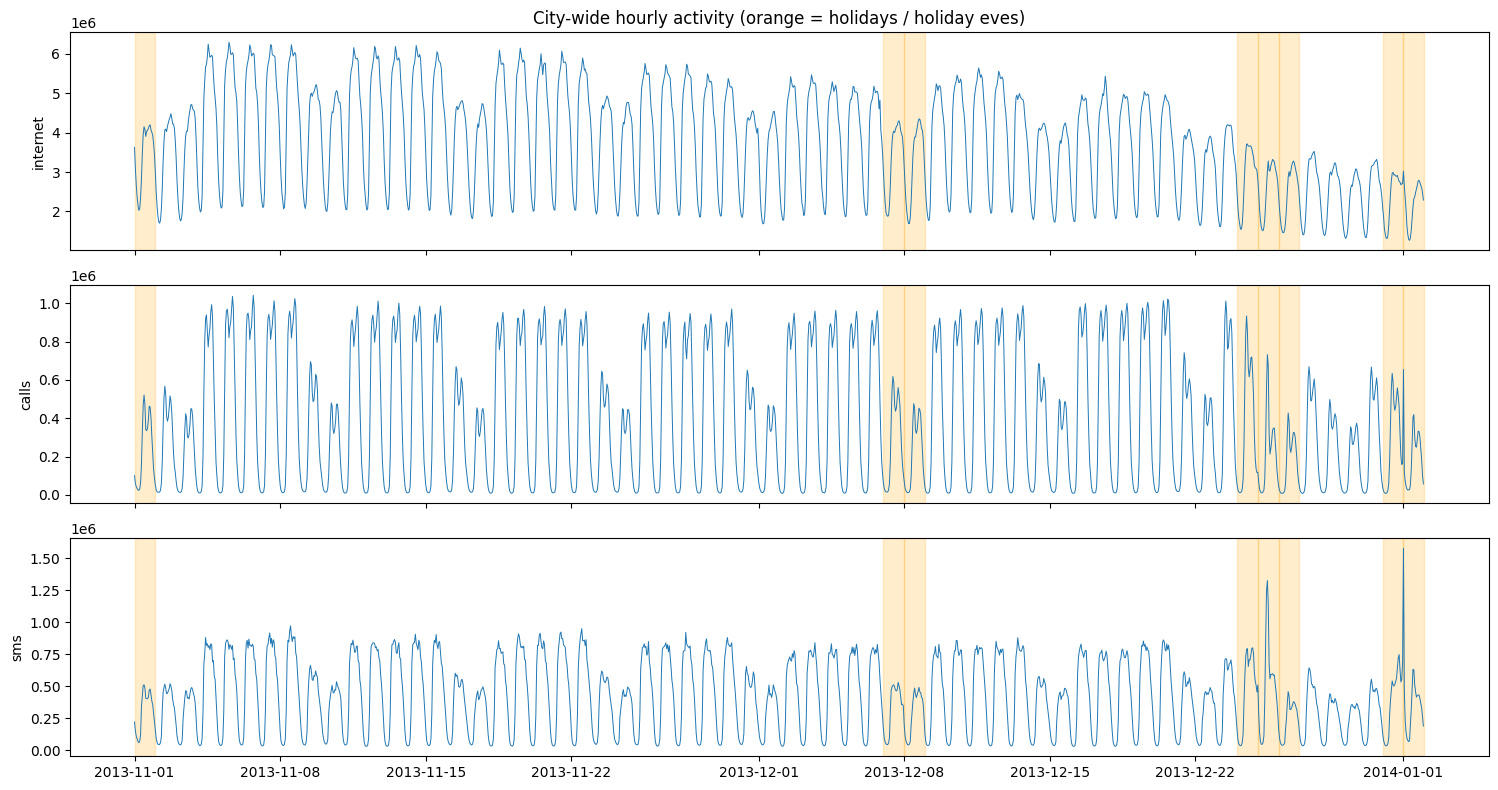

In [5]:
#4 — City-wide traffic over the two months

hours_index = START + pd.to_timedelta(np.arange(N_HOURS), unit="h")
city = pd.DataFrame({"internet": INTERNET.sum(1), "calls": CALLS.sum(1), "sms": SMS.sum(1)}, index=hours_index)

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
for ax, col in zip(axes, city.columns):
    ax.plot(city.index, city[col], lw=0.7)
    ax.set_ylabel(col)
    for d in SPECIAL_DAYS:
        ax.axvspan(pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta(days=1), color="orange", alpha=0.2)
axes[0].set_title("City-wide hourly activity (orange = holidays / holiday eves)")
plt.tight_layout(); savefig("01_city_timeseries.png"); plt.show()

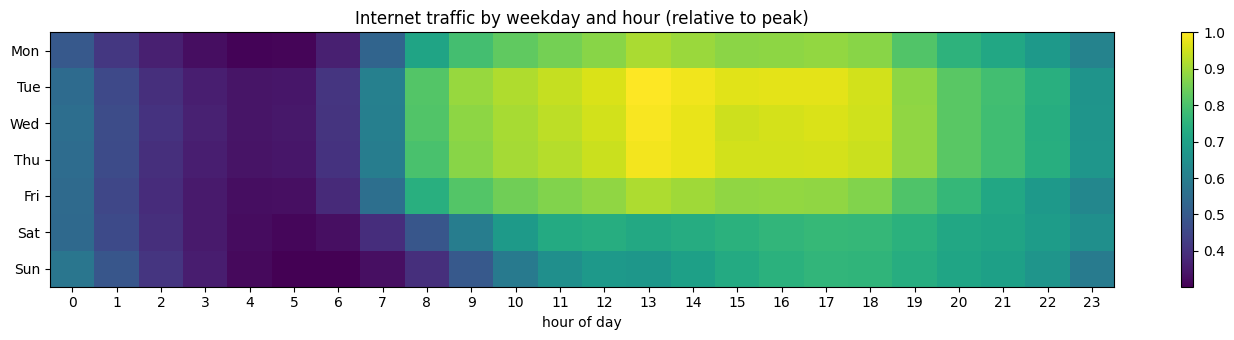

In [6]:
#5 — Weekly pattern: average city internet traffic by day of week and hour (normal days only)

normal_hours = ~np.repeat(special, 24)
prof = city.loc[normal_hours, "internet"]
grid = prof.groupby([prof.index.dayofweek, prof.index.hour]).mean().unstack()
grid.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(14, 3.5))
im = ax.imshow(grid / grid.values.max(), aspect="auto", cmap="viridis")
ax.set_yticks(range(7)); ax.set_yticklabels(grid.index)
ax.set_xticks(range(24)); ax.set_xlabel("hour of day")
ax.set_title("Internet traffic by weekday and hour (relative to peak)")
plt.colorbar(im, ax=ax); plt.tight_layout(); savefig("02_weekly_heatmap.png"); plt.show()

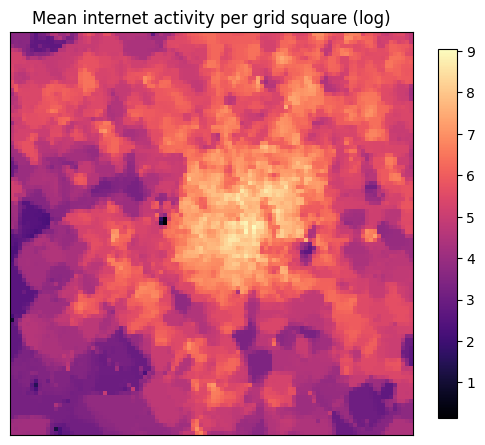

In [7]:
#6 — Where is the traffic? Mean internet activity per square (log scale)
#    Square IDs run along the 100×100 grid row by row; this is an approximate map of Milan.

mean_map = INTERNET.mean(0).reshape(100, 100)
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(np.log1p(mean_map), origin="lower", cmap="magma")
ax.set_title("Mean internet activity per grid square (log)")
ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=ax, shrink=0.8); savefig("03_traffic_map.png"); plt.show()

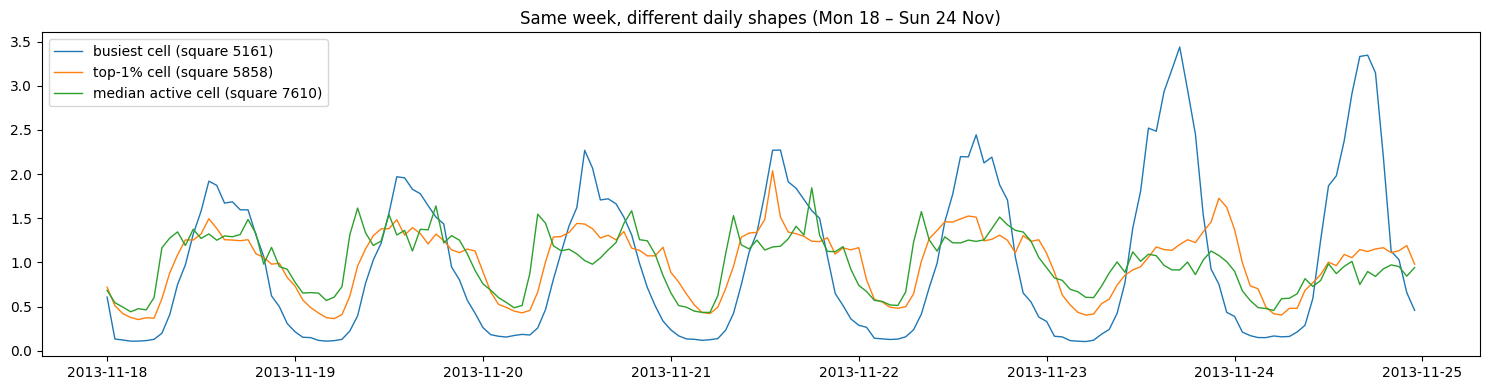

In [8]:
#7 — Cells behave differently: one normal week, each cell scaled to its own mean

wk = slice(day_idx("2013-11-18") * 24, day_idx("2013-11-25") * 24)
cell_mean = INTERNET.mean(0)
active_sorted = np.argsort(cell_mean)[::-1]
examples = {"busiest cell": active_sorted[0],
            "top-1% cell": active_sorted[100],
            "median active cell": active_sorted[np.sum(cell_mean > 0) // 2]}

fig, ax = plt.subplots(figsize=(15, 4))
for label, c in examples.items():
    s = INTERNET[wk, c]
    ax.plot(hours_index[wk], s / s.mean(), lw=1, label=f"{label} (square {c + 1})")
ax.set_title("Same week, different daily shapes (Mon 18 – Sun 24 Nov)")
ax.legend(); plt.tight_layout(); savefig("04_cell_profiles.png"); plt.show()

## 4. Forecasting setup

* **Task:** at midnight, forecast all 24 hours of the next day for each cell. Every feature therefore uses data that is at least 24 hours old.
* **Features:** same hour 1, 2, 3 days and 1, 2, 3 weeks ago; recent averages; hour, weekday, holiday flags; the cell's size and grid position.
* **Cells:** a random sample of `N_CELLS` active cells (seeded, so it's reproducible).
* **Scaling:** each cell is divided by its mean over the training period (1–24 Nov), so one *global* model can learn shared patterns across busy and quiet cells. Training is weighted by that mean, so the loss matches the main metric.
* **Metric — WAPE** (weighted absolute percentage error) = Σ|actual − forecast| / Σ actual. Lower is better; 0.10 means the forecast is off by 10% of total traffic. We also report the *median per-cell WAPE*.

In [9]:
#8 — Splits, cell sample, scaling and feature builder

TRAIN_DAYS = np.arange(day_idx("2013-11-08"), day_idx("2013-11-24") + 1)
VAL_DAYS = np.arange(day_idx("2013-11-25"), day_idx("2013-12-01") + 1)
REFIT_DAYS = np.arange(day_idx("2013-11-08"), day_idx("2013-12-08") + 1)
TEST_DAYS = np.arange(day_idx("2013-12-09"), day_idx("2013-12-22") + 1)
XMAS_DAYS = np.arange(day_idx("2013-12-23"), day_idx("2014-01-01") + 1)

fit_hours = slice(0, (TRAIN_DAYS[-1] + 1) * 24)                      # scaling uses training period only
fit_mean = INTERNET[fit_hours].mean(0)
active = np.where(fit_mean > np.percentile(fit_mean[fit_mean > 0], 5))[0]
rng = np.random.default_rng(SEED)
CELLS = np.sort(rng.choice(active, size=min(N_CELLS, len(active)), replace=False))
SCALE = fit_mean[CELLS]
C = len(CELLS)
print(f"{len(active)} active squares, using {C}")

X = INTERNET[:, CELLS] / SCALE                                     # hours x cells, normalised
DAILY = X.reshape(N_DAYS, 24, C).mean(1)                           # daily mean per cell
DAILY_CUM = np.vstack([np.zeros((1, C)), np.cumsum(DAILY, axis=0)])

def lag_values(T, lag):
    out = np.full((len(T), C), np.nan, dtype="float32")
    ok = T - lag >= 0
    out[ok] = X[T[ok] - lag]
    return out

def build(days):
    """Feature table for every (target hour, cell) in the given days. Row order: hour-major, cell-minor."""
    days = np.asarray(days)
    T = (days[:, None] * 24 + np.arange(24)[None, :]).ravel()
    d, h = T // 24, T % 24
    F = {}
    for lag in (24, 48, 72, 168, 336, 504):
        F[f"lag_{lag}"] = lag_values(T, lag)          # NaN when the lag is before 1 Nov
    same_hour = np.stack([X[T - 24 * k] for k in range(1, 8)])
    F["same_hour_mean_7d"] = same_hour.mean(0)
    F["same_hour_std_7d"] = same_hour.std(0)
    F["weekly_profile_3w"] = np.nanmean(np.stack([F["lag_168"], F["lag_336"], F["lag_504"]]), axis=0)
    F["prev_day_mean"] = DAILY[d - 1]
    F["prev_week_mean"] = (DAILY_CUM[d] - DAILY_CUM[d - 7]) / 7
    F["day_ratio_vs_week"] = F["prev_day_mean"] / (F["prev_week_mean"] + 1e-6)
    df = pd.DataFrame({k: v.ravel() for k, v in F.items()})
    dow = dates[d].dayofweek.to_numpy()
    df["hour"] = np.repeat(h, C)
    df["dow"] = np.repeat(dow, C)
    df["is_weekend"] = np.repeat(dow >= 5, C).astype(int)
    df["special_day"] = np.repeat(special[d], C).astype(int)
    df["special_prev_day"] = np.repeat(special[d - 1], C).astype(int)
    df["special_last_week"] = np.repeat(special[d - 7], C).astype(int)
    df["log_cell_mean"] = np.tile(np.log(SCALE), len(T))
    df["grid_row"] = np.tile(CELLS // 100, len(T))
    df["grid_col"] = np.tile(CELLS % 100, len(T))
    y = X[T].ravel()
    w = np.tile(SCALE, len(T))
    return df.astype("float32"), y, w, T

Xtr, ytr, wtr, Ttr = build(TRAIN_DAYS)
Xva, yva, wva, Tva = build(VAL_DAYS)
Xrf, yrf, wrf, Trf = build(REFIT_DAYS)
Xte, yte, wte, Tte = build(TEST_DAYS)
print(f"rows: train {len(Xtr):,} | val {len(Xva):,} | refit {len(Xrf):,} | test {len(Xte):,} | features {Xtr.shape[1]}")

9497 active squares, using 2000
rows: train 816,000 | val 336,000 | refit 1,488,000 | test 672,000 | features 21


In [10]:
#9 — Metrics and baselines

def wape(y, p, w):
    """WAPE in original traffic units (y, p are normalised; w = cell scale)."""
    return np.sum(np.abs(y - p) * w) / np.sum(y * w)

def median_cell_wape(y, p):
    e = np.abs(y - p).reshape(-1, C).sum(0)
    return np.median(e / y.reshape(-1, C).sum(0))

def baselines(Xf, T):
    return {
        "Yesterday (same hour)": Xf["lag_24"].to_numpy(),
        "Last week (same hour)": Xf["lag_168"].to_numpy(),
        "3-week weekly profile": Xf["weekly_profile_3w"].to_numpy(),
    }

test_preds = baselines(Xte, Tte)
for name, p in test_preds.items():
    print(f"{name:26s} test WAPE {wape(yte, p, wte):.3f} | median cell WAPE {median_cell_wape(yte, p):.3f}")

Yesterday (same hour)      test WAPE 0.158 | median cell WAPE 0.151
Last week (same hour)      test WAPE 0.148 | median cell WAPE 0.135
3-week weekly profile      test WAPE 0.152 | median cell WAPE 0.117


## 5. Global LightGBM model

One model for all cells. It learns, for example, *"this cell is usually 30% busier at 18:00 than its weekly average, but yesterday was unusually quiet"*. Early stopping uses the validation week; the final model is then refitted on 8 Nov – 8 Dec with a proportionally larger number of trees.

In [11]:
#10 — Train LightGBM

import lightgbm as lgb

params = dict(objective="l1", learning_rate=0.05, num_leaves=63, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              n_estimators=3000, importance_type="gain", random_state=SEED, verbose=-1)

t0 = time.time()
model = lgb.LGBMRegressor(**params)
model.fit(Xtr, ytr, sample_weight=wtr,
          eval_set=[(Xva, yva)], eval_sample_weight=[wva],
          callbacks=[lgb.early_stopping(100), lgb.log_evaluation(250)])
best_iter = model.best_iteration_ or params["n_estimators"]
print(f"best iteration: {best_iter}  (val WAPE {wape(yva, model.predict(Xva, num_iteration=best_iter), wva):.3f})")

# Refit on 8 Nov – 8 Dec (scaled to the larger data), then forecast the test period
n_final = int(best_iter * len(REFIT_DAYS) / len(TRAIN_DAYS))
final = lgb.LGBMRegressor(**{**params, "n_estimators": n_final})
final.fit(Xrf, yrf, sample_weight=wrf)
test_preds["LightGBM (global)"] = np.clip(final.predict(Xte), 0, None)
print(f"trained in {time.time() - t0:.0f}s")

Training until validation scores don't improve for 100 rounds
[250]	valid_0's l1: 0.109071
Early stopping, best iteration is:
[329]	valid_0's l1: 0.108732
best iteration: 329  (val WAPE 0.116)
trained in 694s


## 6. Results on the test period (9–22 Dec)

,WAPE,median cell WAPE,WAPE of total (all sampled cells)
model,,,
LightGBM (global),0.102,0.102,0.041
Last week (same hour),0.148,0.135,0.056
3-week weekly profile,0.152,0.117,0.063
Yesterday (same hour),0.158,0.151,0.075


LightGBM vs best baseline (Last week (same hour)): +30.9% error reduction


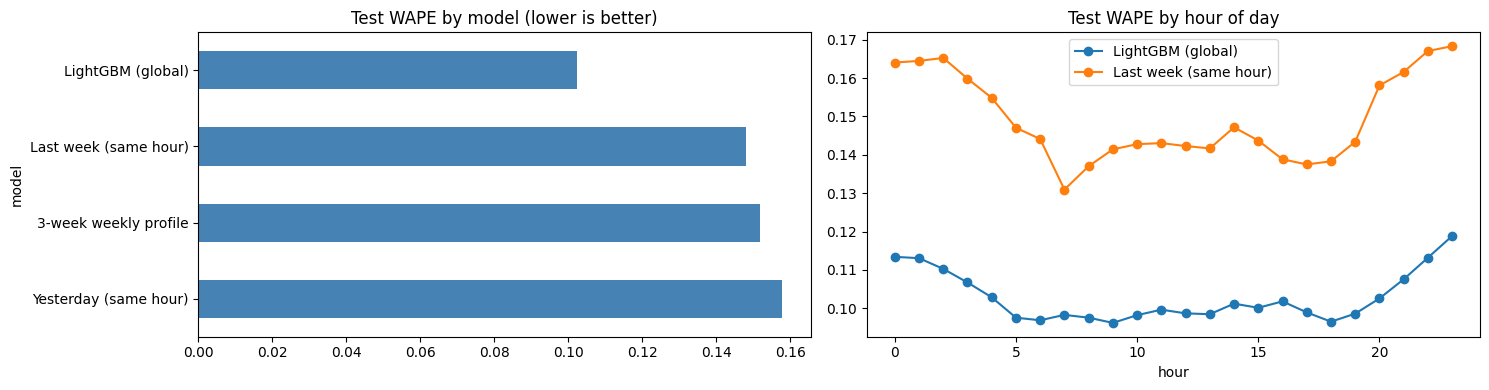

In [12]:
#11 — Results table + charts

rows = []
for name, p in test_preds.items():
    city_true = (yte * wte).reshape(-1, C).sum(1)
    city_pred = (p * wte).reshape(-1, C).sum(1)
    rows.append({"model": name,
                 "WAPE": wape(yte, p, wte),
                 "median cell WAPE": median_cell_wape(yte, p),
                 "WAPE of total (all sampled cells)": np.sum(np.abs(city_true - city_pred)) / city_true.sum()})
results = pd.DataFrame(rows).set_index("model").sort_values("WAPE")
display(results.round(3))
results.round(4).to_csv(os.path.join(OUT_DIR, "test_results.csv"))

best_base = results.drop("LightGBM (global)").index[0]
gain = 1 - results.loc["LightGBM (global)", "WAPE"] / results.loc[best_base, "WAPE"]
print(f"LightGBM vs best baseline ({best_base}): {gain:+.1%} error reduction")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
results["WAPE"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Test WAPE by model (lower is better)"); axes[0].invert_yaxis()

hour_of_row = np.repeat(Tte % 24, C)
for name in ["LightGBM (global)", best_base]:
    p = test_preds[name]
    by_hour = pd.DataFrame({"h": hour_of_row, "e": np.abs(yte - p) * wte, "y": yte * wte}).groupby("h").sum()
    axes[1].plot(by_hour.index, by_hour.e / by_hour.y, marker="o", label=name)
axes[1].set_title("Test WAPE by hour of day"); axes[1].set_xlabel("hour"); axes[1].legend()
plt.tight_layout(); savefig("05_results.png"); plt.show()

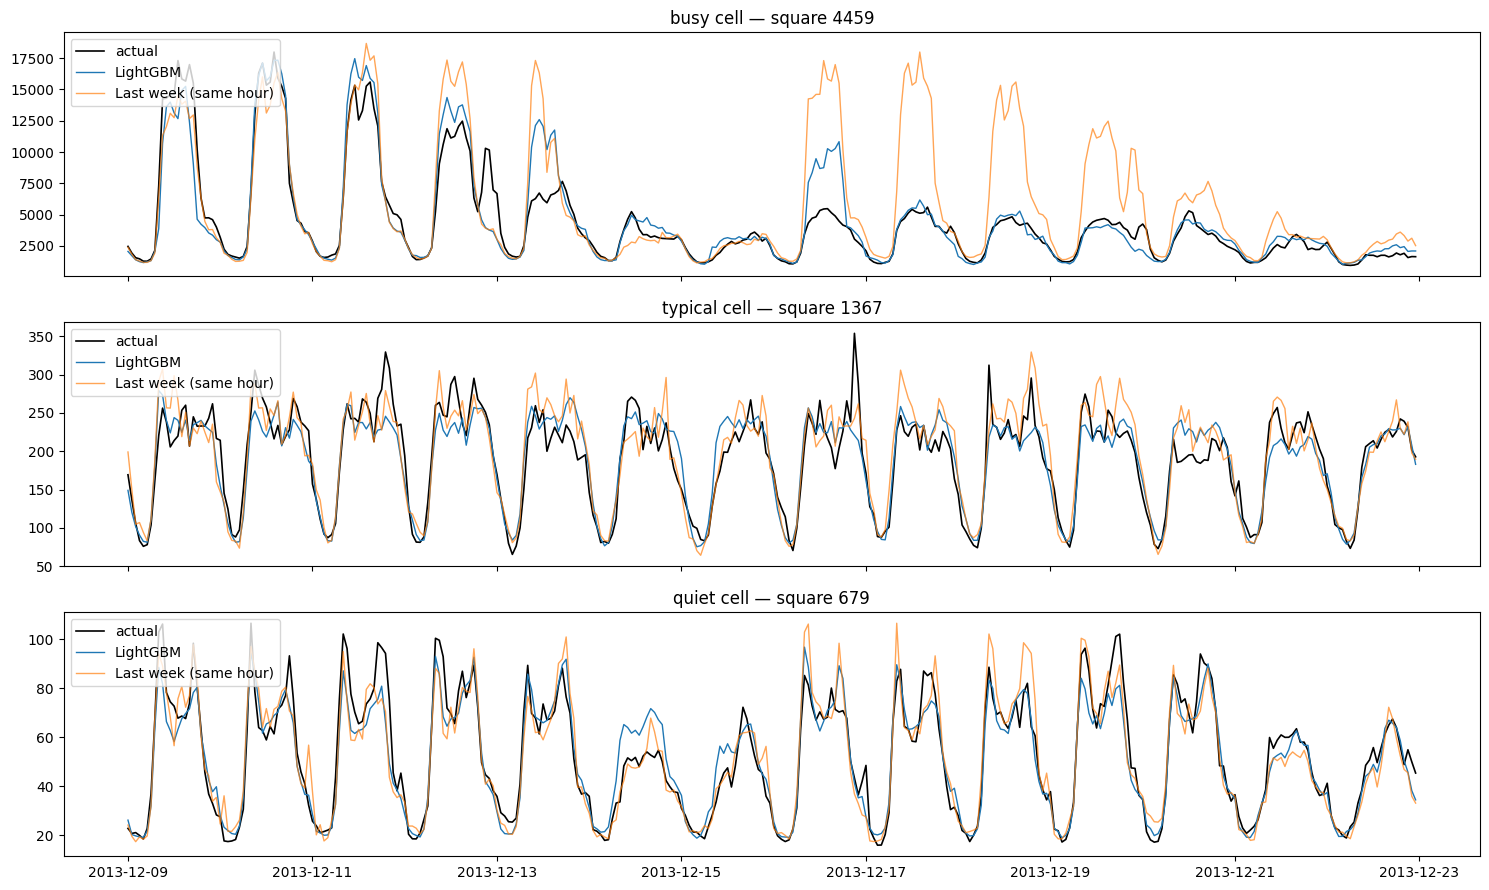

In [13]:
#12 — Forecast vs actual for three cells (test period)

order = np.argsort(SCALE)[::-1]
show = {"busy cell": order[0], "typical cell": order[C // 2], "quiet cell": order[int(C * 0.9)]}
t_idx = hours_index[Tte]

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, (label, j) in zip(axes, show.items()):
    sl = lambda v: v.reshape(-1, C)[:, j] * SCALE[j]
    ax.plot(t_idx, sl(yte), color="black", lw=1.2, label="actual")
    ax.plot(t_idx, sl(test_preds["LightGBM (global)"]), lw=1, label="LightGBM")
    ax.plot(t_idx, sl(test_preds[best_base]), lw=1, alpha=0.7, label=best_base)
    ax.set_title(f"{label} — square {CELLS[j] + 1}"); ax.legend(loc="upper left")
plt.tight_layout(); savefig("06_forecast_examples.png"); plt.show()

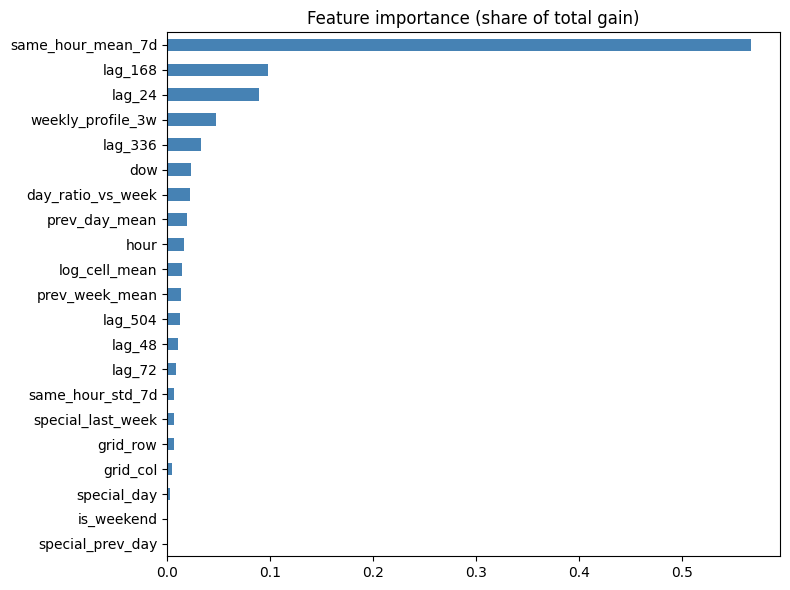

In [14]:
#13 — What does the model rely on?

imp = pd.Series(final.feature_importances_, index=Xtr.columns).sort_values()
(imp / imp.sum()).plot.barh(figsize=(8, 6), color="steelblue")
plt.title("Feature importance (share of total gain)")
plt.tight_layout(); savefig("07_feature_importance.png"); plt.show()

## 7. Christmas stress test (23 Dec – 1 Jan)

The final model saw only two holidays as training targets (7–8 Dec, a weekend). How badly do forecasts break when behaviour changes over Christmas and New Year?

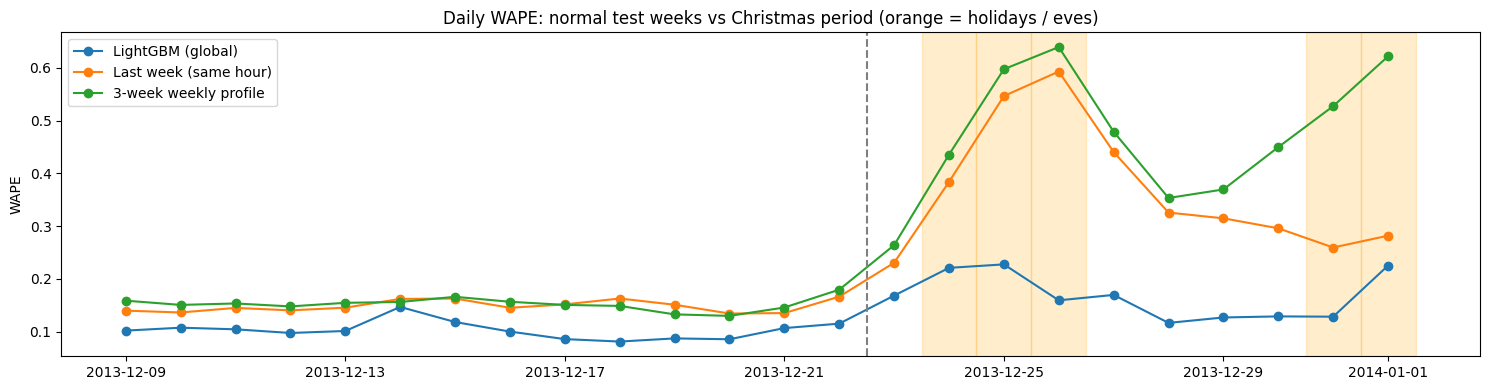

,test 9–22 Dec,holidays 23 Dec–1 Jan
LightGBM (global),0.103,0.167
Last week (same hour),0.149,0.367
3-week weekly profile,0.152,0.474


In [15]:
#14 — Daily error through the test period and the holidays

days = np.concatenate([TEST_DAYS, XMAS_DAYS])
Xh, yh, wh, Th = build(days)
ph = {"LightGBM (global)": np.clip(final.predict(Xh), 0, None),
      "Last week (same hour)": Xh["lag_168"].to_numpy(),
      "3-week weekly profile": Xh["weekly_profile_3w"].to_numpy()}

day_of_row = np.repeat(Th // 24, C)
daily = pd.DataFrame({name: pd.DataFrame({"d": day_of_row, "e": np.abs(yh - p) * wh, "y": yh * wh})
                                .groupby("d").sum().pipe(lambda g: g.e / g.y)
                      for name, p in ph.items()})
daily.index = dates[daily.index]

fig, ax = plt.subplots(figsize=(15, 4))
for col in daily:
    ax.plot(daily.index, daily[col], marker="o", label=col)
for d in SPECIAL_DAYS:
    if pd.Timestamp(d) >= daily.index[0]:
        ax.axvspan(pd.Timestamp(d) - pd.Timedelta(hours=12), pd.Timestamp(d) + pd.Timedelta(hours=12), color="orange", alpha=0.2)
ax.axvline(dates[XMAS_DAYS[0]] - pd.Timedelta(hours=12), color="gray", ls="--")
ax.set_title("Daily WAPE: normal test weeks vs Christmas period (orange = holidays / eves)")
ax.set_ylabel("WAPE"); ax.legend(); plt.tight_layout(); savefig("08_holiday_stress_test.png"); plt.show()

summary = pd.DataFrame({"test 9–22 Dec": daily.loc[dates[TEST_DAYS]].mean(),
                        "holidays 23 Dec–1 Jan": daily.loc[dates[XMAS_DAYS]].mean()})
display(summary.round(3))
summary.round(4).to_csv(os.path.join(OUT_DIR, "holiday_stress_test.csv"))

In [16]:
#15 — Save the model and list the outputs (download the folder for your GitHub repo)

final.booster_.save_model(os.path.join(OUT_DIR, "lightgbm_model.txt"))
for p in sorted(glob.glob(os.path.join(OUT_DIR, "**", "*"), recursive=True)):
    if os.path.isfile(p):
        print(f"{os.path.getsize(p) / 1e6:8.1f} MB  {p}")
# Tip: zip the figures to download them in one go:
# !cd /content/milan_out && zip -r figures.zip figures test_results.csv holiday_stress_test.csv

     0.4 MB  /content/milan_out/figures/01_city_timeseries.png
     0.0 MB  /content/milan_out/figures/02_weekly_heatmap.png
     0.0 MB  /content/milan_out/figures/03_traffic_map.png
     0.1 MB  /content/milan_out/figures/04_cell_profiles.png
     0.1 MB  /content/milan_out/figures/05_results.png
     0.5 MB  /content/milan_out/figures/06_forecast_examples.png
     0.1 MB  /content/milan_out/figures/07_feature_importance.png
     0.1 MB  /content/milan_out/figures/08_holiday_stress_test.png
     0.0 MB  /content/milan_out/holiday_stress_test.csv
     4.4 MB  /content/milan_out/lightgbm_model.txt
   148.1 MB  /content/milan_out/milan_hourly.npz
     0.0 MB  /content/milan_out/test_results.csv


## Next steps (v2 ideas)
* Add a holiday-aware feature set or train on more holidays (e.g. include the Christmas data in training and test on New Year).
* Use neighbouring cells as features (traffic often moves across the city during the day).
* Compare with a deep model (LSTM / Temporal Fusion Transformer) and with Prophet on the city total.
* Probabilistic forecasts (quantile regression) — capacity planning cares about the peaks.

In [17]:
!cd /content/milan_out && zip -r milan_results.zip figures test_results.csv holiday_stress_test.csv lightgbm_model.txt

  adding: figures/ (stored 0%)
  adding: figures/01_city_timeseries.png (deflated 2%)
  adding: figures/05_results.png (deflated 12%)
  adding: figures/06_forecast_examples.png (deflated 2%)
  adding: figures/08_holiday_stress_test.png (deflated 6%)
  adding: figures/04_cell_profiles.png (deflated 4%)
  adding: figures/07_feature_importance.png (deflated 19%)
  adding: figures/02_weekly_heatmap.png (deflated 17%)
  adding: figures/03_traffic_map.png (deflated 6%)
  adding: test_results.csv (deflated 29%)
  adding: holiday_stress_test.csv (deflated 12%)
  adding: lightgbm_model.txt (deflated 57%)
